# 🌾 Crop Yield Prediction with Climate Clustering
## Complete Machine Learning Project — Run Cell by Cell

**Dataset:** Indian Agriculture (1997–2020) | 19,689 records | 55 Crops | 30 States  
**Approach:** K-Means Climate Clustering + Random Forest / XGBoost / LightGBM  
**Target:** Predict crop yield (tonnes/hectare)  

---
> ▶️ **How to use:** Run each cell top to bottom using **Shift + Enter**
> All plots, models and reports are auto-generated.

| Section | What it does |
|---|---|
| 1 | Install & Import Libraries |
| 2 | Configuration |
| 3 | Load & Inspect Data |
| 4 | Exploratory Data Analysis |
| 5 | Data Preprocessing |
| 6 | Climate Clustering (K-Means) |
| 7 | Feature Engineering |
| 8 | Model Training |
| 9 | Model Evaluation |
| 10 | Predict New Crops |

SECTION 1 — Install & Import Libraries

In [1]:
# 1.1 
import subprocess, sys

packages = [
    'numpy', 'pandas', 'matplotlib', 'seaborn',
    'scikit-learn', 'xgboost', 'lightgbm', 'plotly', 'joblib'
]

for pkg in packages:
    try:
        __import__(pkg.replace('-', '_'))
        print(f'  ✅ {pkg} already installed')
    except ImportError:
        print(f'  📦 Installing {pkg} ...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])
        print(f'  ✅ {pkg} installed')

print('\n🎉 All libraries ready!')

  ✅ numpy already installed
  ✅ pandas already installed
  ✅ matplotlib already installed
  ✅ seaborn already installed
  📦 Installing scikit-learn ...
  ✅ scikit-learn installed
  ✅ xgboost already installed
  ✅ lightgbm already installed
  ✅ plotly already installed
  ✅ joblib already installed

🎉 All libraries ready!


In [2]:
# import all libraries
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# Interactive plots
import plotly.express as px
import plotly.graph_objects as go

# ML — preprocessing
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import (mean_squared_error,
                              mean_absolute_error,
                              r2_score, silhouette_score)

# ML — models
from sklearn.ensemble import (RandomForestRegressor,
                               GradientBoostingRegressor)
from sklearn.linear_model import Ridge

# XGBoost
try:
    import xgboost as xgb
    XGB_OK = True
    print('✅ XGBoost available')
except ImportError:
    XGB_OK = False
    print('⚠️  XGBoost not found — will use GradientBoosting instead')

# LightGBM
try:
    import lightgbm as lgb
    LGB_OK = True
    print('✅ LightGBM available')
except ImportError:
    LGB_OK = False
    print('⚠️  LightGBM not found — will use GradientBoosting instead')

print('\n✅ All imports successful!')

✅ XGBoost available
✅ LightGBM available

✅ All imports successful!


SECTION 2 — Configuration

In [3]:
# all configuration constants
# ── FILE PATH ────────────────────────────────────────────────
# Change this if your file is somewhere else
DATA_PATH = r"C:\Users\Samrudhhi\crop_yield_prediction\data\raw\crop_yield.csv"

# ── COLUMN NAMES ─────────────────────────────────────────────
TARGET_COL     = 'Yield'
CROP_COL       = 'Crop'
YEAR_COL       = 'Crop_Year'
SEASON_COL     = 'Season'
STATE_COL      = 'State'
AREA_COL       = 'Area'
PRODUCTION_COL = 'Production'
RAINFALL_COL   = 'Annual_Rainfall'
FERTILIZER_COL = 'Fertilizer'
PESTICIDE_COL  = 'Pesticide'
CLUSTER_COL    = 'Climate_Cluster'

CATEGORICAL_COLS = [CROP_COL, SEASON_COL, STATE_COL]
NUMERICAL_COLS   = [AREA_COL, PRODUCTION_COL, RAINFALL_COL,
                    FERTILIZER_COL, PESTICIDE_COL]

# ── PREPROCESSING ─────────────────────────────────────────────
LOG_TRANSFORM_COLS = [AREA_COL, PRODUCTION_COL,
                      FERTILIZER_COL, PESTICIDE_COL, TARGET_COL]
OUTLIER_CAP_LOWER  = 0.01
OUTLIER_CAP_UPPER  = 0.99
TRAIN_CUTOFF_YEAR  = 2015   # Train ≤ 2015 | Test > 2015
RANDOM_STATE       = 42

# ── CLUSTERING ────────────────────────────────────────────────
OPTIMAL_N_CLUSTERS = 4
CLUSTER_LABELS     = {0:'Arid', 1:'Semi-Arid',
                      2:'Moderate', 3:'Humid'}
CLUSTER_COLOR_MAP  = {0:'#E74C3C', 1:'#F39C12',
                      2:'#27AE60', 3:'#2980B9'}

# ── MODEL HYPERPARAMETERS ─────────────────────────────────────
RF_PARAMS = {
    'n_estimators':300, 'max_depth':15,
    'min_samples_split':5, 'min_samples_leaf':2,
    'max_features':'sqrt', 'random_state':RANDOM_STATE, 'n_jobs':-1
}
XGB_PARAMS = {
    'n_estimators':500, 'learning_rate':0.05, 'max_depth':7,
    'subsample':0.8, 'colsample_bytree':0.8,
    'reg_alpha':0.1, 'reg_lambda':1.0,
    'random_state':RANDOM_STATE, 'n_jobs':-1, 'verbosity':0
}
LGB_PARAMS = {
    'n_estimators':500, 'learning_rate':0.05, 'max_depth':7,
    'num_leaves':63, 'subsample':0.8, 'colsample_bytree':0.8,
    'random_state':RANDOM_STATE, 'n_jobs':-1, 'verbose':-1
}
CV_FOLDS   = 5
FIGURE_DPI = 150

# ── CREATE OUTPUT FOLDERS ─────────────────────────────────────
os.makedirs('models',        exist_ok=True)
os.makedirs('outputs/plots', exist_ok=True)

print('✅ Configuration set!')
print(f'   Data file    : {DATA_PATH}')
print(f'   Train years  : up to {TRAIN_CUTOFF_YEAR}')
print(f'   Test years   : {TRAIN_CUTOFF_YEAR+1} onwards')
print(f'   Clusters     : {OPTIMAL_N_CLUSTERS}')
print(f'   Folders      : models/ and outputs/plots/ ready')

✅ Configuration set!
   Data file    : C:\Users\Samrudhhi\crop_yield_prediction\data\raw\crop_yield.csv
   Train years  : up to 2015
   Test years   : 2016 onwards
   Clusters     : 4
   Folders      : models/ and outputs/plots/ ready


SECTION 3 — Load & Inspect Data

In [4]:
# 3.1 Load Dataset
df_raw = pd.read_csv(DATA_PATH)

# Strip whitespace from text columns
for col in CATEGORICAL_COLS:
    df_raw[col] = df_raw[col].str.strip()

print(f'✅ Dataset loaded!')
print(f'   Rows    : {len(df_raw):,}')
print(f'   Columns : {df_raw.shape[1]}')
print(f'   Memory  : {df_raw.memory_usage(deep=True).sum()/1024:.1f} KB')
print()
df_raw.head(10)

✅ Dataset loaded!
   Rows    : 19,689
   Columns : 10
   Memory  : 4373.0 KB



,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909
5,Dry chillies,1997,Whole Year,Assam,13587.0,9073,2051.4,1293074.79,4211.97,0.643636
6,Gram,1997,Rabi,Assam,2979.0,1507,2051.4,283511.43,923.49,0.465455
7,Jute,1997,Kharif,Assam,94520.0,904095,2051.4,8995468.40,29301.20,9.919565
8,Linseed,1997,Rabi,Assam,10098.0,5158,2051.4,961026.66,3130.38,0.461364
9,Maize,1997,Kharif,Assam,19216.0,14721,2051.4,1828786.72,5956.96,0.615652


In [5]:
#3.2 Dataset Summary
print('='*55)
print('  DATASET OVERVIEW')
print('='*55)
print(f'  Year range : {df_raw[YEAR_COL].min()} – {df_raw[YEAR_COL].max()}')
print(f'  Crops      : {df_raw[CROP_COL].nunique()} unique')
print(f'  States     : {df_raw[STATE_COL].nunique()} unique')
print(f'  Seasons    : {df_raw[SEASON_COL].nunique()} unique')
print(f'  Missing    : {df_raw.isnull().sum().sum()} values')
print()
print('Yield statistics:')
print(df_raw[TARGET_COL].describe().round(2).to_string())
print()
print('Column data types:')
print(df_raw.dtypes.to_string())

  DATASET OVERVIEW
  Year range : 1997 – 2020
  Crops      : 55 unique
  States     : 30 unique
  Seasons    : 6 unique
  Missing    : 0 values

Yield statistics:
count    19689.00
mean        79.95
std        878.31
min          0.00
25%          0.60
50%          1.03
75%          2.39
max      21105.00

Column data types:
Crop                   str
Crop_Year            int64
Season                 str
State                  str
Area               float64
Production           int64
Annual_Rainfall    float64
Fertilizer         float64
Pesticide          float64
Yield              float64


In [6]:
# 3.3 class distribution
print('Season Distribution:')
print(df_raw[SEASON_COL].value_counts().to_string())
print()
print('Top 10 Crops by record count:')
print(df_raw[CROP_COL].value_counts().head(10).to_string())
print()
print('Records per State:')
print(df_raw[STATE_COL].value_counts().to_string())

Season Distribution:
Season
Kharif        8232
Rabi          5742
Whole Year    3717
Summer        1195
Autumn         414
Winter         389

Top 10 Crops by record count:
Crop
Rice                 1197
Maize                 975
Moong(Green Gram)     740
Urad                  733
Groundnut             725
Sesamum               685
Potato                628
Sugarcane             605
Wheat                 545
Rapeseed &Mustard     528

Records per State:
State
Karnataka            1432
Andhra Pradesh       1266
West Bengal          1094
Chhattisgarh          915
Bihar                 896
Madhya Pradesh        845
Uttar Pradesh         825
Tamil Nadu            822
Gujarat               817
Maharashtra           770
Uttarakhand           764
Odisha                760
Assam                 731
Nagaland              689
Puducherry            670
Meghalaya             649
Haryana               631
Jammu and Kashmir     631
Himachal Pradesh      616
Kerala                534
Manipur         

 SECTION 4 — Exploratory Data Analysis

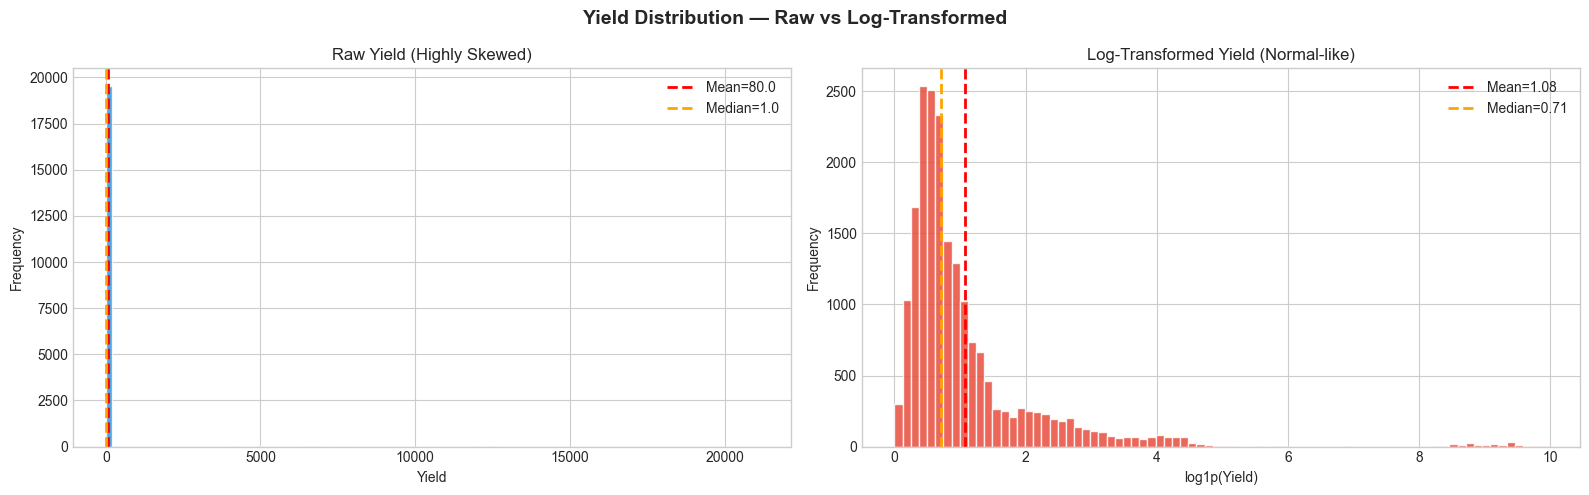

Skewness Raw : 12.79
Skewness Log : 3.66  ← much better after log transform


In [7]:
# Yield Distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Yield Distribution — Raw vs Log-Transformed',
             fontsize=14, fontweight='bold')

axes[0].hist(df_raw[TARGET_COL], bins=100,
             color='#3498DB', edgecolor='white', alpha=0.85)
axes[0].axvline(df_raw[TARGET_COL].mean(),   color='red',
                ls='--', lw=2, label=f"Mean={df_raw[TARGET_COL].mean():.1f}")
axes[0].axvline(df_raw[TARGET_COL].median(), color='orange',
                ls='--', lw=2, label=f"Median={df_raw[TARGET_COL].median():.1f}")
axes[0].set(xlabel='Yield', ylabel='Frequency', title='Raw Yield (Highly Skewed)')
axes[0].legend()

log_yield = np.log1p(df_raw[TARGET_COL])
axes[1].hist(log_yield, bins=80,
             color='#E74C3C', edgecolor='white', alpha=0.85)
axes[1].axvline(log_yield.mean(),   color='red',
                ls='--', lw=2, label=f"Mean={log_yield.mean():.2f}")
axes[1].axvline(log_yield.median(), color='orange',
                ls='--', lw=2, label=f"Median={log_yield.median():.2f}")
axes[1].set(xlabel='log1p(Yield)', ylabel='Frequency',
            title='Log-Transformed Yield (Normal-like)')
axes[1].legend()

plt.tight_layout()
plt.savefig('outputs/plots/eda_01_yield_distribution.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()
print(f'Skewness Raw : {df_raw[TARGET_COL].skew():.2f}')
print(f'Skewness Log : {log_yield.skew():.2f}  ← much better after log transform')

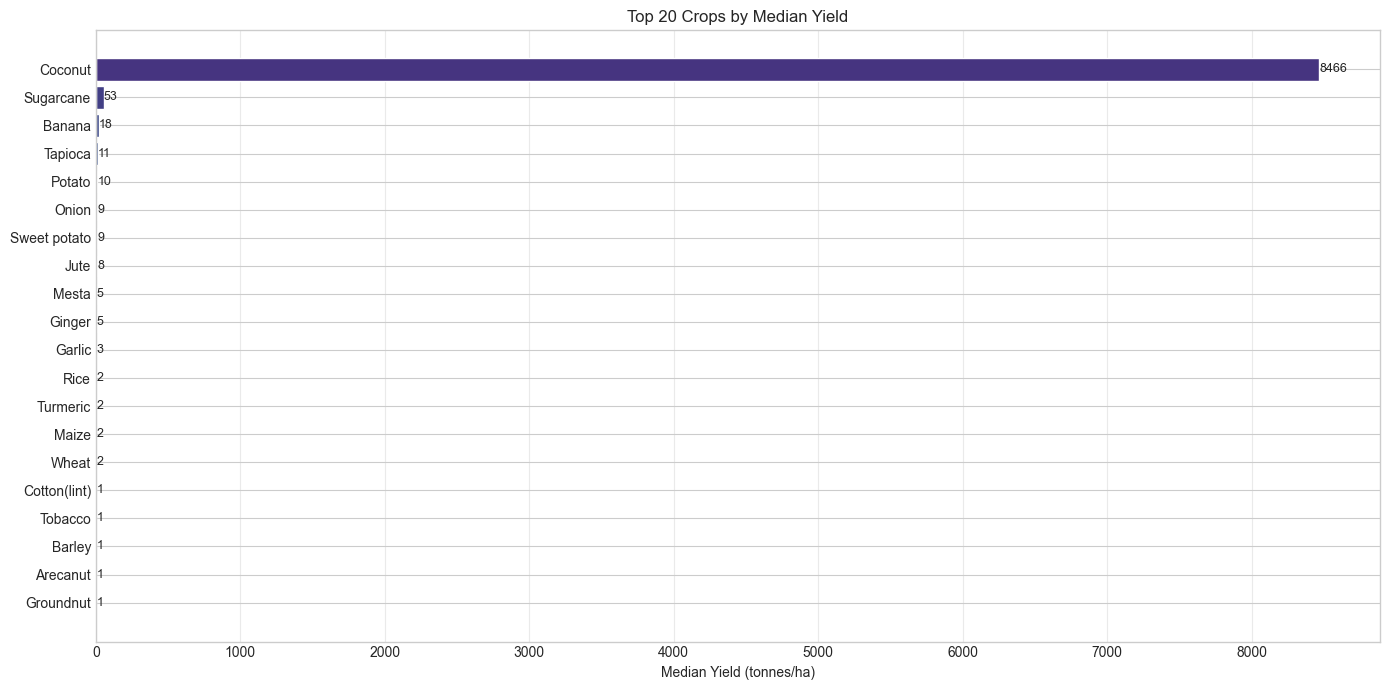

In [8]:
top_crops = (df_raw.groupby(CROP_COL)[TARGET_COL]
             .median()
             .sort_values(ascending=False)
             .head(20))

fig, ax = plt.subplots(figsize=(14, 7))
colors = plt.cm.viridis(np.linspace(0.15, 0.85, 20))[::-1]
bars = ax.barh(top_crops.index[::-1], top_crops.values[::-1],
               color=colors, edgecolor='white')
ax.set(xlabel='Median Yield (tonnes/ha)',
       title='Top 20 Crops by Median Yield')
ax.grid(axis='x', alpha=0.4)
for bar, val in zip(bars, top_crops.values[::-1]):
    ax.text(bar.get_width()+2, bar.get_y()+bar.get_height()/2,
            f'{val:.0f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('outputs/plots/eda_02_top_crops.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

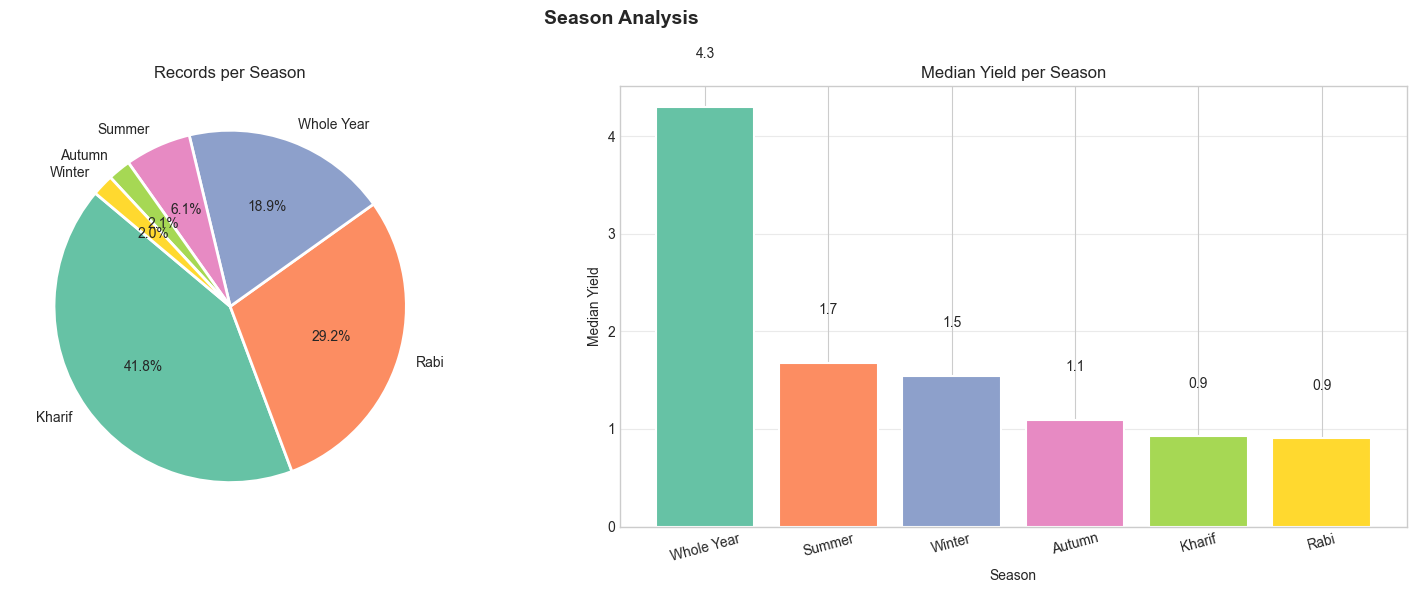

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Season Analysis', fontsize=14, fontweight='bold')

sc = df_raw[SEASON_COL].value_counts()
axes[0].pie(sc.values, labels=sc.index, autopct='%1.1f%%',
            startangle=140,
            colors=sns.color_palette('Set2', len(sc)),
            wedgeprops=dict(edgecolor='white', linewidth=2))
axes[0].set_title('Records per Season')

sy = df_raw.groupby(SEASON_COL)[TARGET_COL].median().sort_values(ascending=False)
bars = axes[1].bar(sy.index, sy.values,
                   color=sns.color_palette('Set2', len(sy)),
                   edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, sy.values):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                 f'{val:.1f}', ha='center', fontsize=10)
axes[1].set(xlabel='Season', ylabel='Median Yield',
            title='Median Yield per Season')
axes[1].grid(axis='y', alpha=0.4)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('outputs/plots/eda_03_season_analysis.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

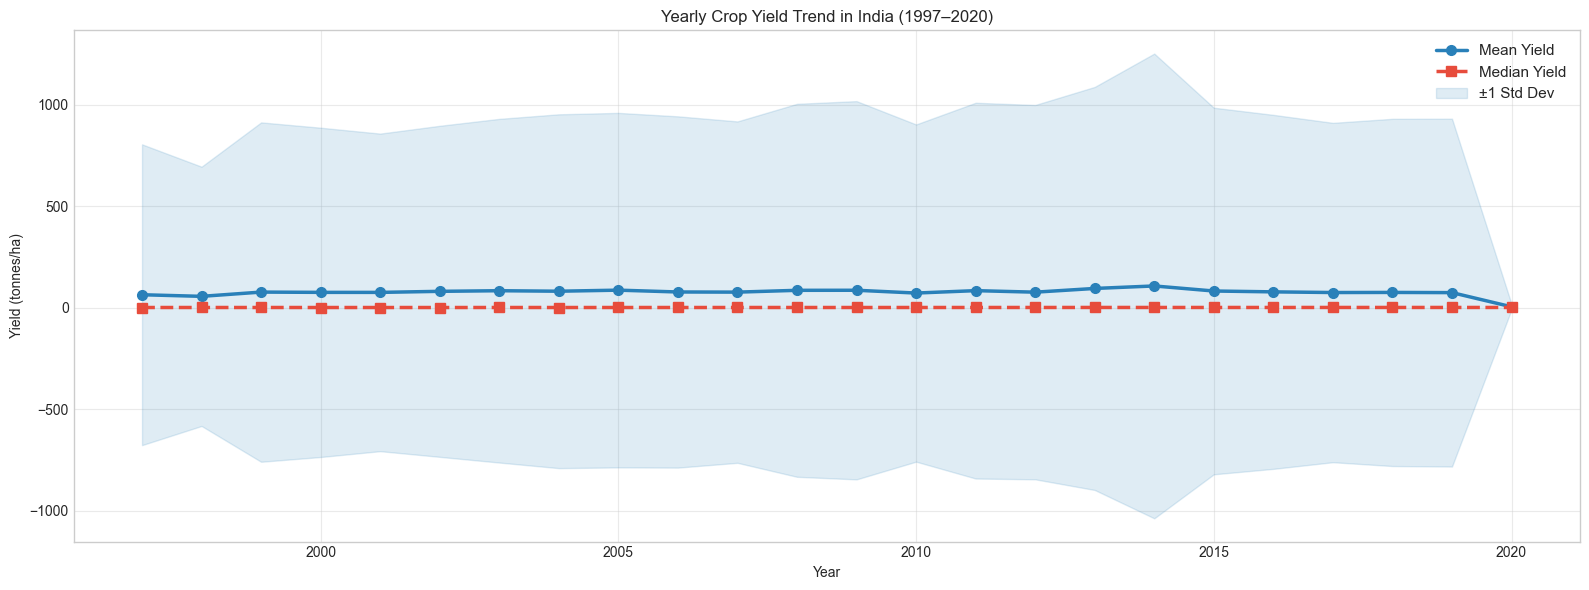

In [10]:
yearly = (df_raw.groupby(YEAR_COL)[TARGET_COL]
          .agg(['mean','median','std'])
          .reset_index())

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(yearly[YEAR_COL], yearly['mean'],   'o-',
        color='#2980B9', lw=2.5, ms=7, label='Mean Yield')
ax.plot(yearly[YEAR_COL], yearly['median'], 's--',
        color='#E74C3C', lw=2.5, ms=7, label='Median Yield')
ax.fill_between(yearly[YEAR_COL],
                yearly['mean'] - yearly['std'],
                yearly['mean'] + yearly['std'],
                alpha=0.15, color='#2980B9', label='±1 Std Dev')
ax.set(xlabel='Year', ylabel='Yield (tonnes/ha)',
       title='Yearly Crop Yield Trend in India (1997–2020)')
ax.legend(fontsize=11)
ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/plots/eda_04_yearly_trend.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

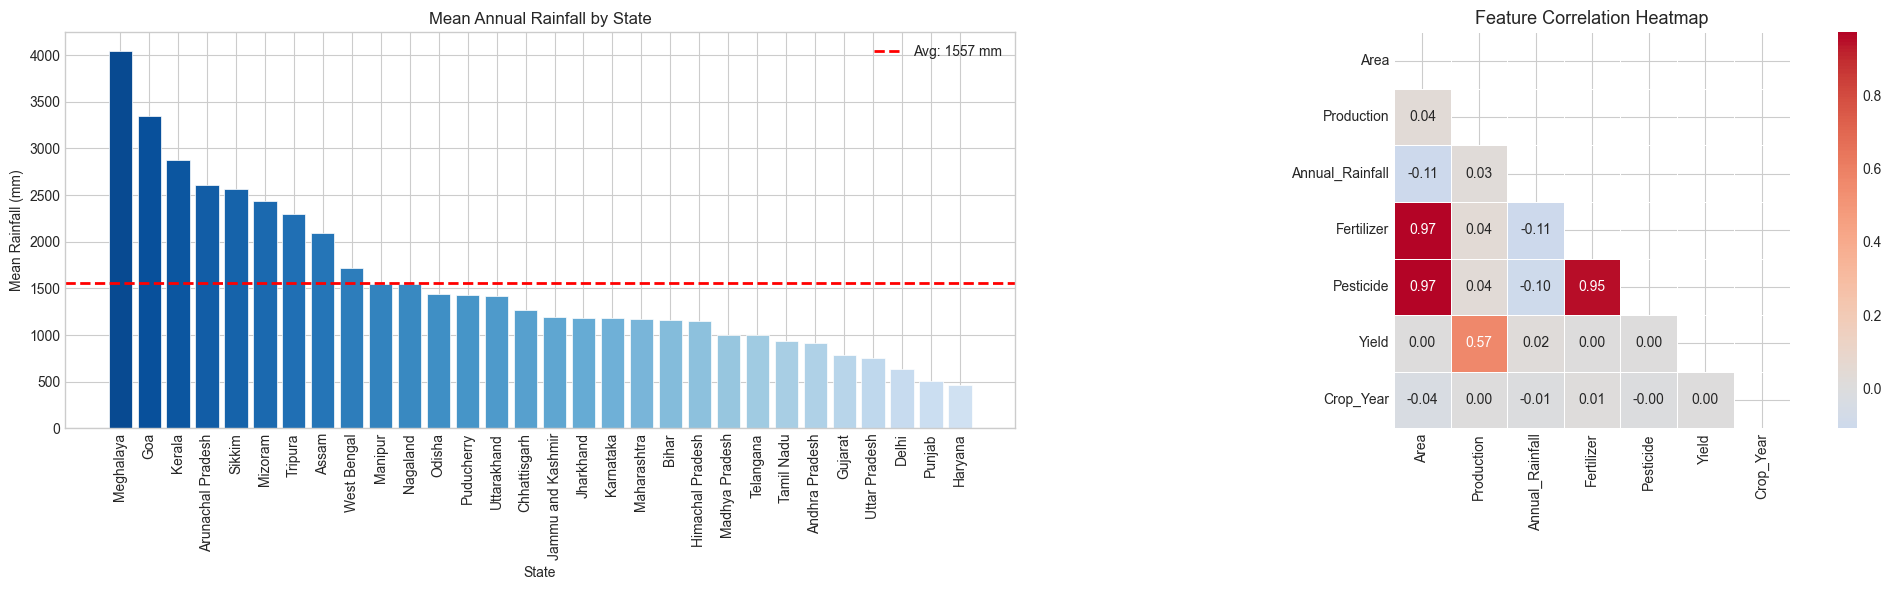

Correlations with Yield:
Production         0.570809
Annual_Rainfall    0.020761
Fertilizer         0.002862
Crop_Year          0.002539
Area               0.001858
Pesticide          0.001782


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

# Rainfall by state
sr = df_raw.groupby(STATE_COL)[RAINFALL_COL].mean().sort_values(ascending=False)
axes[0].bar(sr.index, sr.values,
            color=plt.cm.Blues_r(np.linspace(0.1, 0.8, len(sr))),
            edgecolor='white', linewidth=0.5)
axes[0].axhline(sr.mean(), color='red', ls='--', lw=2,
                label=f'Avg: {sr.mean():.0f} mm')
axes[0].set(xlabel='State', ylabel='Mean Rainfall (mm)',
            title='Mean Annual Rainfall by State')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=90)

# Correlation heatmap
corr_cols = [AREA_COL, PRODUCTION_COL, RAINFALL_COL,
             FERTILIZER_COL, PESTICIDE_COL, TARGET_COL, YEAR_COL]
corr = df_raw[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=axes[1],
            linewidths=0.5, annot_kws={'size':10}, square=True)
axes[1].set_title('Feature Correlation Heatmap', fontsize=13)

plt.tight_layout()
plt.savefig('outputs/plots/eda_05_rainfall_correlation.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

print('Correlations with Yield:')
print(corr[TARGET_COL].drop(TARGET_COL).sort_values(ascending=False).to_string())

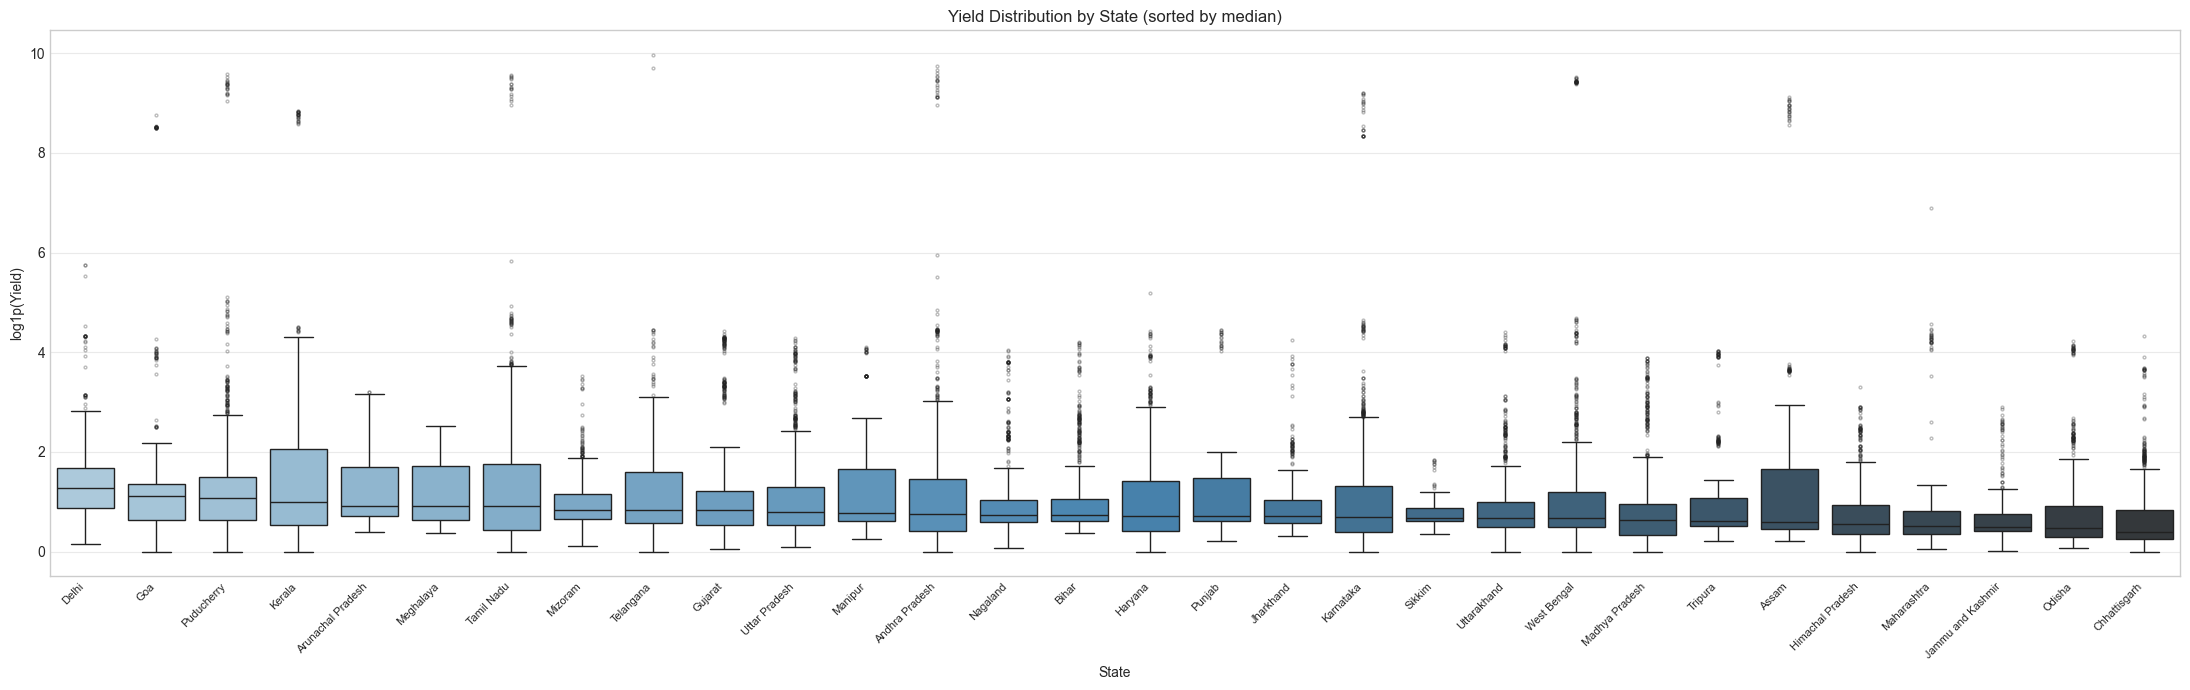

In [12]:
state_order = (df_raw.groupby(STATE_COL)[TARGET_COL]
               .median()
               .sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(22, 7))
df_plot = df_raw.copy()
df_plot[TARGET_COL] = np.log1p(df_plot[TARGET_COL])
sns.boxplot(data=df_plot, x=STATE_COL, y=TARGET_COL,
            order=state_order, ax=ax, palette='Blues_d',
            flierprops=dict(marker='o', markersize=2, alpha=0.3))
ax.set(xlabel='State', ylabel='log1p(Yield)',
       title='Yield Distribution by State (sorted by median)')
plt.xticks(rotation=45, ha='right', fontsize=8)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/plots/eda_06_yield_by_state.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

SECTION 5 — Data Preprocessing

In [13]:
df = df_raw.copy()

print('Capping outliers at 1st–99th percentile ...')
for col in [FERTILIZER_COL, PESTICIDE_COL, AREA_COL, PRODUCTION_COL]:
    lo = df[col].quantile(OUTLIER_CAP_LOWER)
    hi = df[col].quantile(OUTLIER_CAP_UPPER)
    n  = ((df[col] < lo) | (df[col] > hi)).sum()
    df[col] = df[col].clip(lo, hi)
    print(f'  {col:20s}: {n} outliers capped  [{lo:.1f}, {hi:.1f}]')

df[TARGET_COL] = df[TARGET_COL].clip(
    upper=df[TARGET_COL].quantile(0.999))
print(f'  {TARGET_COL:20s}: capped at 99.9th percentile')
print('\n✅ Outlier capping done!')

Capping outliers at 1st–99th percentile ...
  Fertilizer          : 391 outliers capped  [400.2, 442726956.7]
  Pesticide           : 390 outliers capped  [0.7, 885873.3]
  Area                : 380 outliers capped  [3.0, 3299225.6]
  Production          : 388 outliers capped  [2.0, 37571119.6]
  Yield               : capped at 99.9th percentile

✅ Outlier capping done!


In [14]:
print('Applying log1p transform to skewed columns ...')
for col in LOG_TRANSFORM_COLS:
    before_skew = df[col].skew()
    df[col] = np.log1p(df[col].clip(lower=0))
    after_skew  = df[col].skew()
    print(f'  {col:20s}: skew {before_skew:+.2f} → {after_skew:+.2f}')

print('\n✅ Log transform done!')

Applying log1p transform to skewed columns ...
  Area                : skew +4.84 → -0.33
  Production          : skew +7.13 → -0.13
  Fertilizer          : skew +4.87 → -0.36
  Pesticide           : skew +4.88 → -0.27
  Yield               : skew +12.35 → +3.65

✅ Log transform done!


In [15]:
print('Label-encoding categorical columns ...')
encoders = {}
for col in CATEGORICAL_COLS:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le
    print(f'  {col:10s}: {len(le.classes_)} classes encoded')

# ✅ Fixed path
os.makedirs('../models', exist_ok=True)
joblib.dump(encoders, '../models/encoders.pkl')
print('\n✅ Encoders saved → ../models/encoders.pkl')

Label-encoding categorical columns ...
  Crop      : 55 classes encoded
  Season    : 6 classes encoded
  State     : 30 classes encoded

✅ Encoders saved → ../models/encoders.pkl


In [16]:
# Temporal split — no data leakage!
train_df = df[df[YEAR_COL] <= TRAIN_CUTOFF_YEAR].copy()
test_df  = df[df[YEAR_COL] >  TRAIN_CUTOFF_YEAR].copy()

print('Temporal Train / Test Split')
print(f'  Train: {len(train_df):,} rows  (Crop_Year ≤ {TRAIN_CUTOFF_YEAR})')
print(f'  Test : {len(test_df):,} rows  (Crop_Year >  {TRAIN_CUTOFF_YEAR})')
print(f'  Split: {len(train_df)/len(df)*100:.1f}% train / {len(test_df)/len(df)*100:.1f}% test')
print('\n✅ Split done! (temporal — no data leakage)')

Temporal Train / Test Split
  Train: 15,404 rows  (Crop_Year ≤ 2015)
  Test : 4,285 rows  (Crop_Year >  2015)
  Split: 78.2% train / 21.8% test

✅ Split done! (temporal — no data leakage)


In [17]:
scale_cols = [
    c for c in df.columns
    if c not in [TARGET_COL, YEAR_COL, CLUSTER_COL]
    and df[c].dtype in ['float64', 'int64']
]

scaler = StandardScaler()
df[scale_cols]       = scaler.fit_transform(df[scale_cols])
train_df[scale_cols] = scaler.transform(train_df[scale_cols])
test_df[scale_cols]  = scaler.transform(test_df[scale_cols])

# ✅ Fixed paths
os.makedirs('../models', exist_ok=True)
joblib.dump(scaler,     '../models/scaler.pkl')
joblib.dump(scale_cols, '../models/scale_cols.pkl')

print(f'✅ Scaled {len(scale_cols)} columns')
print(f'   Scaler saved → ../models/scaler.pkl')
print(f'\nScaled columns:')
print(scale_cols)

✅ Scaled 8 columns
   Scaler saved → ../models/scaler.pkl

Scaled columns:
['Crop', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']


SECTION 6 — Climate Clustering (K-Means)

In [18]:
state_profile = (df_raw.groupby(STATE_COL)[RAINFALL_COL]
                 .agg(
                     Rainfall_Mean='mean',
                     Rainfall_Std='std',
                     Rainfall_Min='min',
                     Rainfall_Max='max'
                 )
                 .fillna(0)
                 .reset_index())

print('State Rainfall Profile (sorted by mean):')
print(state_profile.sort_values('Rainfall_Mean', ascending=False)
      .to_string(index=False))

State Rainfall Profile (sorted by mean):
            State  Rainfall_Mean  Rainfall_Std  Rainfall_Min  Rainfall_Max
        Meghalaya    4043.080340   1116.893901        2448.4        6552.7
              Goa    3352.626275    604.548466        2516.3        4489.5
           Kerala    2877.605431    338.003878        2187.6        3489.6
Arunachal Pradesh    2609.750000    432.155056        1701.9        3616.7
           Sikkim    2570.335298    401.557917        1650.5        3350.1
          Mizoram    2435.757834    475.869408        1665.2        3865.8
          Tripura    2302.765966    401.373142        1764.3        3326.8
            Assam    2095.066161    233.079257        1727.1        2578.5
      West Bengal    1721.623126    265.003432        1096.0        2318.1
          Manipur    1546.946085    398.169599         687.7        2160.5
         Nagaland    1545.550732    198.473555        1225.9        1959.8
           Odisha    1445.279474    183.928455        1066.

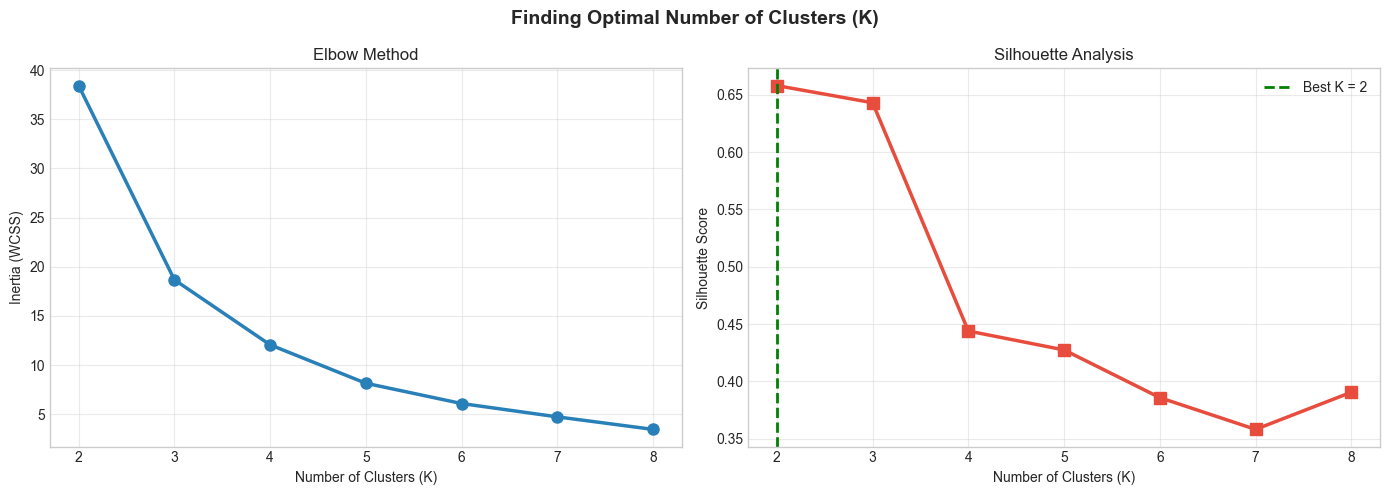

Best K by silhouette : 2
Using K              : 4 (as configured)


In [19]:
feat_cols = ['Rainfall_Mean','Rainfall_Std','Rainfall_Min','Rainfall_Max']
X_states  = state_profile[feat_cols].values
c_scaler  = StandardScaler()
X_scaled  = c_scaler.fit_transform(X_states)

k_range     = range(2, 9)
inertias    = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    lbl = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lbl))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Finding Optimal Number of Clusters (K)',
             fontsize=14, fontweight='bold')

axes[0].plot(list(k_range), inertias, 'o-',
             color='#2980B9', lw=2.5, ms=8)
axes[0].set(xlabel='Number of Clusters (K)',
            ylabel='Inertia (WCSS)', title='Elbow Method')
axes[0].grid(alpha=0.4)

axes[1].plot(list(k_range), silhouettes, 's-',
             color='#E74C3C', lw=2.5, ms=8)
best_k = list(k_range)[silhouettes.index(max(silhouettes))]
axes[1].axvline(best_k, color='green', ls='--', lw=2,
                label=f'Best K = {best_k}')
axes[1].set(xlabel='Number of Clusters (K)',
            ylabel='Silhouette Score', title='Silhouette Analysis')
axes[1].legend()
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.savefig('outputs/plots/cluster_01_elbow.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()
print(f'Best K by silhouette : {best_k}')
print(f'Using K              : {OPTIMAL_N_CLUSTERS} (as configured)')

In [20]:
km_model = KMeans(n_clusters=OPTIMAL_N_CLUSTERS,
                  random_state=RANDOM_STATE, n_init=20)
state_profile[CLUSTER_COL] = km_model.fit_predict(X_scaled)

# Sort clusters: 0 = driest → 3 = wettest
order = (state_profile.groupby(CLUSTER_COL)['Rainfall_Mean']
         .mean().sort_values().index.tolist())
remap = {old: new for new, old in enumerate(order)}
state_profile[CLUSTER_COL] = state_profile[CLUSTER_COL].map(remap)
state_profile['Zone'] = state_profile[CLUSTER_COL].map(CLUSTER_LABELS)

# Save state → cluster mapping
state_cluster_map = dict(zip(state_profile[STATE_COL],
                             state_profile[CLUSTER_COL]))

# ✅ Fixed paths
os.makedirs('../models', exist_ok=True)
joblib.dump(km_model,          '../models/kmeans_cluster.pkl')
joblib.dump(c_scaler,          '../models/cluster_scaler.pkl')
joblib.dump(state_cluster_map, '../models/state_cluster_map.pkl')

# Add cluster column to all dataframes
df_raw_ref = pd.read_csv(DATA_PATH)
for col in CATEGORICAL_COLS:
    df_raw_ref[col] = df_raw_ref[col].str.strip()

df[CLUSTER_COL]       = df_raw_ref[STATE_COL].map(state_cluster_map).values
train_df[CLUSTER_COL] = df_raw_ref.loc[train_df.index, STATE_COL].map(state_cluster_map).values
test_df[CLUSTER_COL]  = df_raw_ref.loc[test_df.index,  STATE_COL].map(state_cluster_map).values

print('State → Climate Zone Assignments:')
print('-'*55)
for _, row in state_profile.sort_values(CLUSTER_COL).iterrows():
    c = int(row[CLUSTER_COL])
    print(f"  {row[STATE_COL]:27s} → Cluster {c}: {CLUSTER_LABELS[c]:12s} ({row['Rainfall_Mean']:.0f} mm/yr)")
print('\n✅ Clusters saved → ../models/')

State → Climate Zone Assignments:
-------------------------------------------------------
  Andhra Pradesh              → Cluster 0: Arid         (916 mm/yr)
  Delhi                       → Cluster 0: Arid         (633 mm/yr)
  Gujarat                     → Cluster 0: Arid         (785 mm/yr)
  Haryana                     → Cluster 0: Arid         (467 mm/yr)
  Tamil Nadu                  → Cluster 0: Arid         (931 mm/yr)
  Uttar Pradesh               → Cluster 0: Arid         (758 mm/yr)
  Punjab                      → Cluster 0: Arid         (509 mm/yr)
  Chhattisgarh                → Cluster 1: Semi-Arid    (1267 mm/yr)
  Karnataka                   → Cluster 1: Semi-Arid    (1182 mm/yr)
  Madhya Pradesh              → Cluster 1: Semi-Arid    (1003 mm/yr)
  Maharashtra                 → Cluster 1: Semi-Arid    (1176 mm/yr)
  Jharkhand                   → Cluster 1: Semi-Arid    (1183 mm/yr)
  Manipur                     → Cluster 1: Semi-Arid    (1547 mm/yr)
  Jammu and Kashmir 

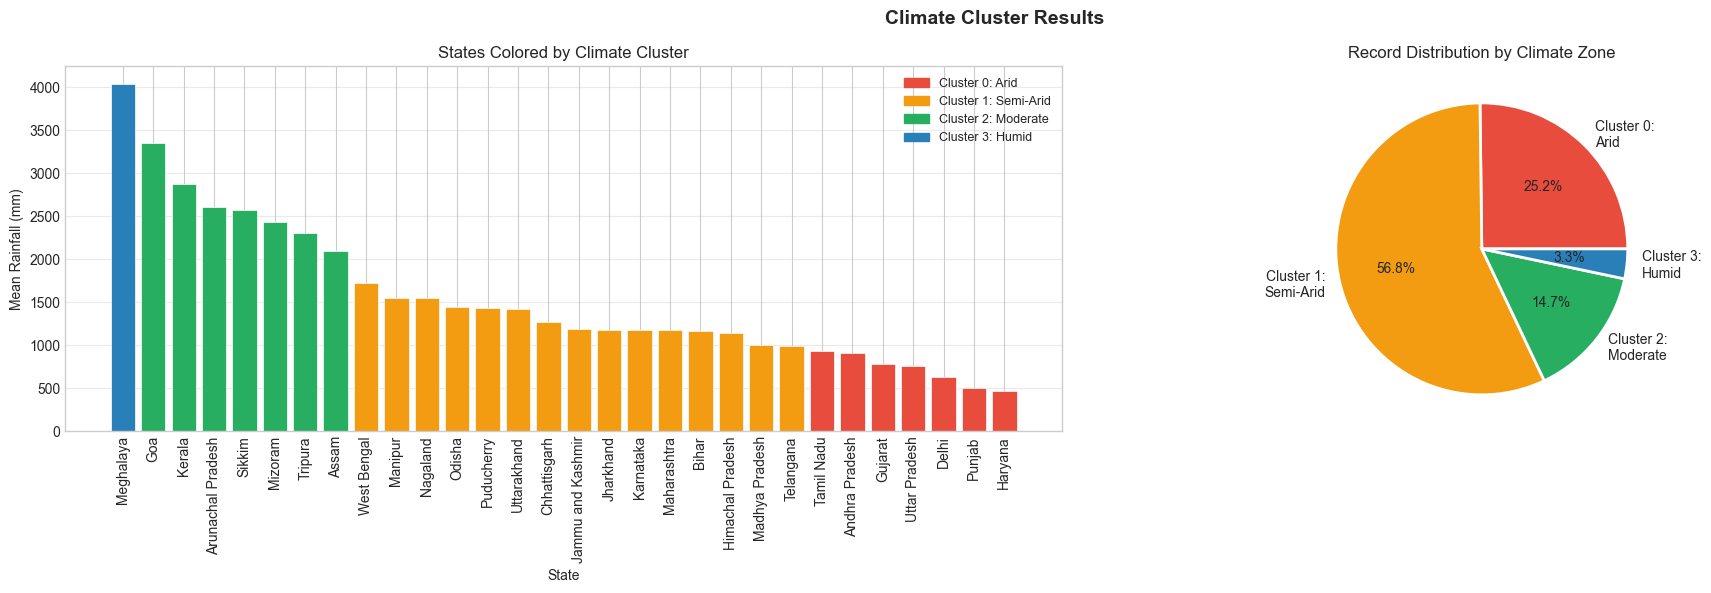

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
fig.suptitle('Climate Cluster Results', fontsize=14, fontweight='bold')

# Bar chart
sp_sorted = state_profile.sort_values('Rainfall_Mean', ascending=False)
colors = [CLUSTER_COLOR_MAP[int(c)] for c in sp_sorted[CLUSTER_COL]]
axes[0].bar(sp_sorted[STATE_COL], sp_sorted['Rainfall_Mean'],
            color=colors, edgecolor='white', linewidth=0.5)
axes[0].set(xlabel='State', ylabel='Mean Rainfall (mm)',
            title='States Colored by Climate Cluster')
axes[0].tick_params(axis='x', rotation=90)
patches = [mpatches.Patch(color=CLUSTER_COLOR_MAP[k],
                           label=f'Cluster {k}: {v}')
           for k, v in CLUSTER_LABELS.items()]
axes[0].legend(handles=patches, fontsize=9)
axes[0].grid(axis='y', alpha=0.4)

# Pie chart
cluster_counts = (df_raw_ref[STATE_COL]
                  .map(state_cluster_map)
                  .value_counts()
                  .sort_index())
pie_labels = [f'Cluster {k}:\n{CLUSTER_LABELS[k]}' for k in cluster_counts.index]
pie_colors = [CLUSTER_COLOR_MAP[k] for k in cluster_counts.index]
axes[1].pie(cluster_counts.values, labels=pie_labels,
            autopct='%1.1f%%', colors=pie_colors,
            wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('Record Distribution by Climate Zone')

plt.tight_layout()
plt.savefig('outputs/plots/cluster_02_zones.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

SECTION 7 — Feature Engineering

In [22]:
def engineer_features(d):
    d   = d.copy()
    eps = 1e-6
    d['Fertilizer_per_Area']        = d[FERTILIZER_COL] / (d[AREA_COL] + eps)
    d['Pesticide_per_Area']         = d[PESTICIDE_COL]  / (d[AREA_COL] + eps)
    d['Fertilizer_Pesticide_Ratio'] = d[FERTILIZER_COL] / (d[PESTICIDE_COL] + eps)
    d['Production_per_Area']        = d[PRODUCTION_COL] / (d[AREA_COL] + eps)
    d['Year_Trend']                 = d[YEAR_COL] - d[YEAR_COL].min()
    return d

df       = engineer_features(df)
train_df = engineer_features(train_df)
test_df  = engineer_features(test_df)

new_features = ['Fertilizer_per_Area', 'Pesticide_per_Area',
                'Fertilizer_Pesticide_Ratio', 'Production_per_Area',
                'Year_Trend']

print('✅ New features created:')
for f in new_features:
    print(f'   {f}')
print(f'\nTotal columns now: {len(df.columns)}')

✅ New features created:
   Fertilizer_per_Area
   Pesticide_per_Area
   Fertilizer_Pesticide_Ratio
   Production_per_Area
   Year_Trend

Total columns now: 16


In [23]:
EXCLUDE_COLS = [TARGET_COL, PRODUCTION_COL, 'Production_per_Area']
FEATURE_COLS = [c for c in df.columns
                if c not in EXCLUDE_COLS
                and df[c].isnull().sum() == 0]

X_train = train_df[FEATURE_COLS].values
y_train = train_df[TARGET_COL].values
X_test  = test_df[FEATURE_COLS].values
y_test  = test_df[TARGET_COL].values

# ✅ Fixed path
os.makedirs('../models', exist_ok=True)
joblib.dump(FEATURE_COLS, '../models/feature_cols.pkl')

print(f'✅ Feature selection done!')
print(f'   Train set : {X_train.shape[0]:,} rows × {X_train.shape[1]} features')
print(f'   Test set  : {X_test.shape[0]:,} rows × {X_test.shape[1]} features')
print(f'\nFinal features used:')
for i, f in enumerate(FEATURE_COLS, 1):
    print(f'   {i:2d}. {f}')

✅ Feature selection done!
   Train set : 15,404 rows × 13 features
   Test set  : 4,285 rows × 13 features

Final features used:
    1. Crop
    2. Crop_Year
    3. Season
    4. State
    5. Area
    6. Annual_Rainfall
    7. Fertilizer
    8. Pesticide
    9. Climate_Cluster
   10. Fertilizer_per_Area
   11. Pesticide_per_Area
   12. Fertilizer_Pesticide_Ratio
   13. Year_Trend


SECTION 8 — Model Training

In [24]:
models = {
    'Ridge Regression' : Ridge(alpha=1.0),
    'Random Forest'    : RandomForestRegressor(**RF_PARAMS),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05,
        max_depth=5, subsample=0.8, random_state=RANDOM_STATE),
}

if XGB_OK:
    models['XGBoost']  = xgb.XGBRegressor(**XGB_PARAMS)
    print('✅ XGBoost added')
if LGB_OK:
    models['LightGBM'] = lgb.LGBMRegressor(**LGB_PARAMS)
    print('✅ LightGBM added')

print(f'\n{len(models)} models ready to train:')
for name in models:
    print(f'  • {name}')

✅ XGBoost added
✅ LightGBM added

5 models ready to train:
  • Ridge Regression
  • Random Forest
  • Gradient Boosting
  • XGBoost
  • LightGBM


In [25]:
print('Running 5-Fold Cross Validation ...')
print('='*55)
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train,
                             cv=kf, scoring='r2', n_jobs=-1)
    cv_results[name] = scores
    print(f'  {name:25s} | R² = {scores.mean():.4f} ± {scores.std():.4f}')

print('='*55)
best_cv = max(cv_results, key=lambda k: cv_results[k].mean())
print(f'\n🏆 Best CV model: {best_cv}  (R² = {cv_results[best_cv].mean():.4f})')

Running 5-Fold Cross Validation ...
  Ridge Regression          | R² = 0.1454 ± 0.0110
  Random Forest             | R² = 0.7974 ± 0.0067
  Gradient Boosting         | R² = 0.9138 ± 0.0049
  XGBoost                   | R² = 0.9419 ± 0.0088
  LightGBM                  | R² = 0.9367 ± 0.0058

🏆 Best CV model: XGBoost  (R² = 0.9419)


In [26]:
def evaluate(y_true, y_pred, name):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    yr   = np.expm1(y_true)
    yp   = np.expm1(y_pred)
    return {
        'Model'    : name,
        'R2'       : round(r2,   4),
        'RMSE_log' : round(rmse, 4),
        'MAE_log'  : round(mae,  4),
        'RMSE_real': round(np.sqrt(mean_squared_error(yr, yp)), 2),
        'MAE_real' : round(mean_absolute_error(yr, yp), 2),
    }

print('Training all models on full train set ...')
print('='*60)
results = []
trained = {}

# ✅ Fixed paths
os.makedirs('../models', exist_ok=True)

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    m = evaluate(y_test, y_pred, name)
    results.append(m)
    trained[name] = model
    safe = name.replace(' ','_').lower()
    joblib.dump(model, f'../models/{safe}.pkl')
    print(f'  {name:25s} | R²={m["R2"]:.4f}  RMSE={m["RMSE_log"]:.4f}  MAE={m["MAE_log"]:.4f}')

results_df = pd.DataFrame(results).set_index('Model')
best_name  = results_df['R2'].idxmax()
best_model = trained[best_name]
joblib.dump(best_model, '../models/best_model.pkl')

print('='*60)
print(f'\n🏆 Best Model: {best_name}  →  R² = {results_df.loc[best_name,"R2"]}')
print(f'   Saved → ../models/best_model.pkl')

Training all models on full train set ...
  Ridge Regression          | R²=0.1118  RMSE=1.0456  MAE=0.6328
  Random Forest             | R²=0.7377  RMSE=0.5682  MAE=0.3841
  Gradient Boosting         | R²=0.8751  RMSE=0.3921  MAE=0.2562
  XGBoost                   | R²=0.9274  RMSE=0.2989  MAE=0.1918
  LightGBM                  | R²=0.9194  RMSE=0.3150  MAE=0.2041

🏆 Best Model: XGBoost  →  R² = 0.9274
   Saved → ../models/best_model.pkl


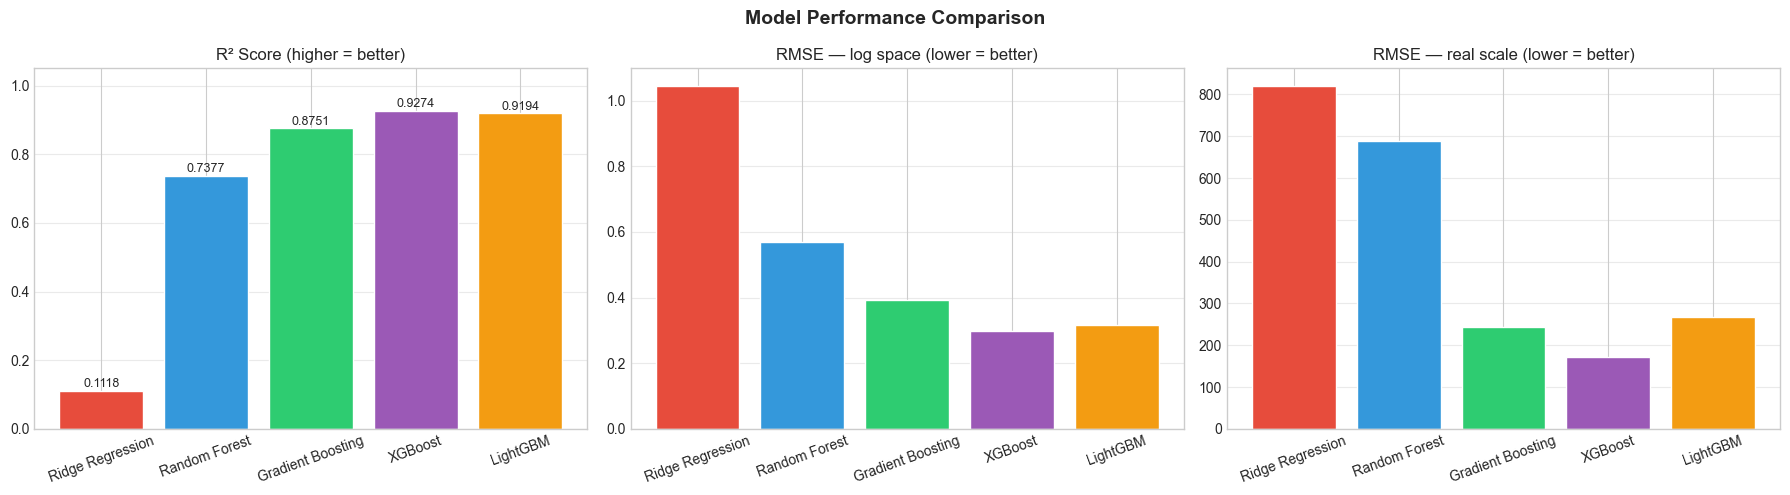


Full Results Table:


,R2,RMSE_log,MAE_log,RMSE_real,MAE_real
Model,,,,,
Ridge Regression,0.1118,1.0456,0.6328,821.33,72.39
Random Forest,0.7377,0.5682,0.3841,688.12,57.40
Gradient Boosting,0.8751,0.3921,0.2562,243.19,18.64
XGBoost,0.9274,0.2989,0.1918,172.43,13.59
LightGBM,0.9194,0.3150,0.2041,266.74,20.00


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
colors = ['#E74C3C','#3498DB','#2ECC71','#9B59B6','#F39C12'][:len(results_df)]

bars = axes[0].bar(results_df.index, results_df['R2'],
                   color=colors, edgecolor='white')
axes[0].set(title='R² Score (higher = better)', ylim=(0, 1.05))
axes[0].grid(axis='y', alpha=0.4)
for bar, val in zip(bars, results_df['R2']):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                 f'{val:.4f}', ha='center', fontsize=9)
axes[0].tick_params(axis='x', rotation=20)

axes[1].bar(results_df.index, results_df['RMSE_log'],
            color=colors, edgecolor='white')
axes[1].set(title='RMSE — log space (lower = better)')
axes[1].grid(axis='y', alpha=0.4)
axes[1].tick_params(axis='x', rotation=20)

axes[2].bar(results_df.index, results_df['RMSE_real'],
            color=colors, edgecolor='white')
axes[2].set(title='RMSE — real scale (lower = better)')
axes[2].grid(axis='y', alpha=0.4)
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('outputs/plots/model_01_comparison.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

print('\nFull Results Table:')
results_df

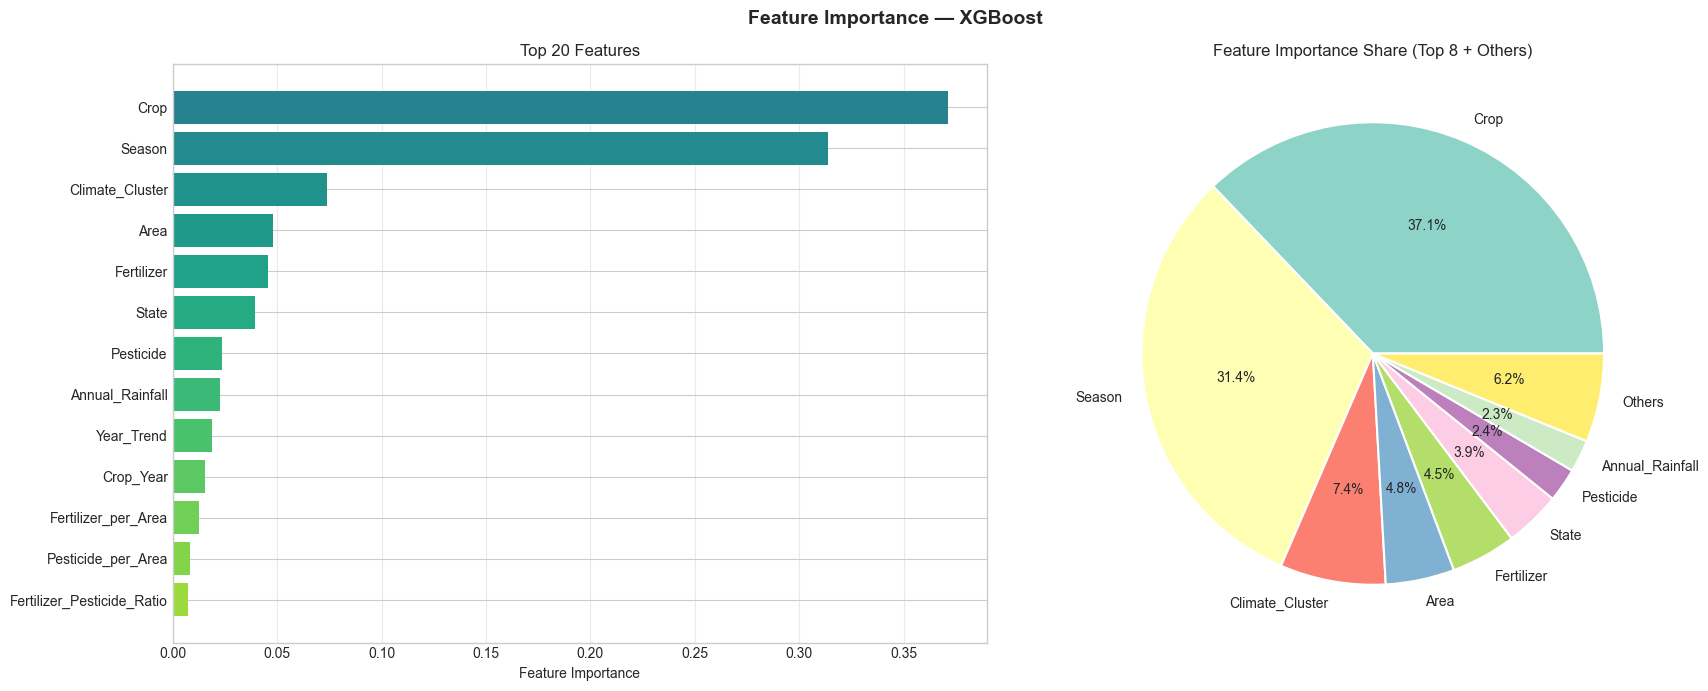

Top 10 Most Important Features:
   1. Crop                                0.3714
   2. Season                              0.3137
   3. Climate_Cluster                     0.0739
   4. Area                                0.0481
   5. Fertilizer                          0.0455
   6. State                               0.0394
   7. Pesticide                           0.0236
   8. Annual_Rainfall                     0.0225
   9. Year_Trend                          0.0186
  10. Crop_Year                           0.0154


In [28]:
if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_,
                    index=FEATURE_COLS).sort_values(ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle(f'Feature Importance — {best_name}',
                 fontsize=14, fontweight='bold')

    top20 = imp.head(20)
    axes[0].barh(top20.index[::-1], top20.values[::-1],
                 color=plt.cm.viridis(np.linspace(0.2, 0.85, 20))[::-1])
    axes[0].set(xlabel='Feature Importance', title='Top 20 Features')
    axes[0].grid(axis='x', alpha=0.4)

    top8    = imp.head(8)
    others  = imp.iloc[8:].sum()
    pie_vals = list(top8.values) + [others]
    pie_lbls = list(top8.index)  + ['Others']
    axes[1].pie(pie_vals, labels=pie_lbls, autopct='%1.1f%%',
                colors=plt.cm.Set3(np.linspace(0, 1, len(pie_vals))),
                wedgeprops=dict(edgecolor='white', linewidth=1.5))
    axes[1].set_title('Feature Importance Share (Top 8 + Others)')

    plt.tight_layout()
    plt.savefig('outputs/plots/model_02_feature_importance.png',
                dpi=FIGURE_DPI, bbox_inches='tight')
    plt.show()

    print('Top 10 Most Important Features:')
    for i, (feat, val) in enumerate(imp.head(10).items(), 1):
        print(f'  {i:2d}. {feat:35s} {val:.4f}')
else:
    print(f'{best_name} does not support feature importance.')

SECTION 9 — Deep Model Evaluation

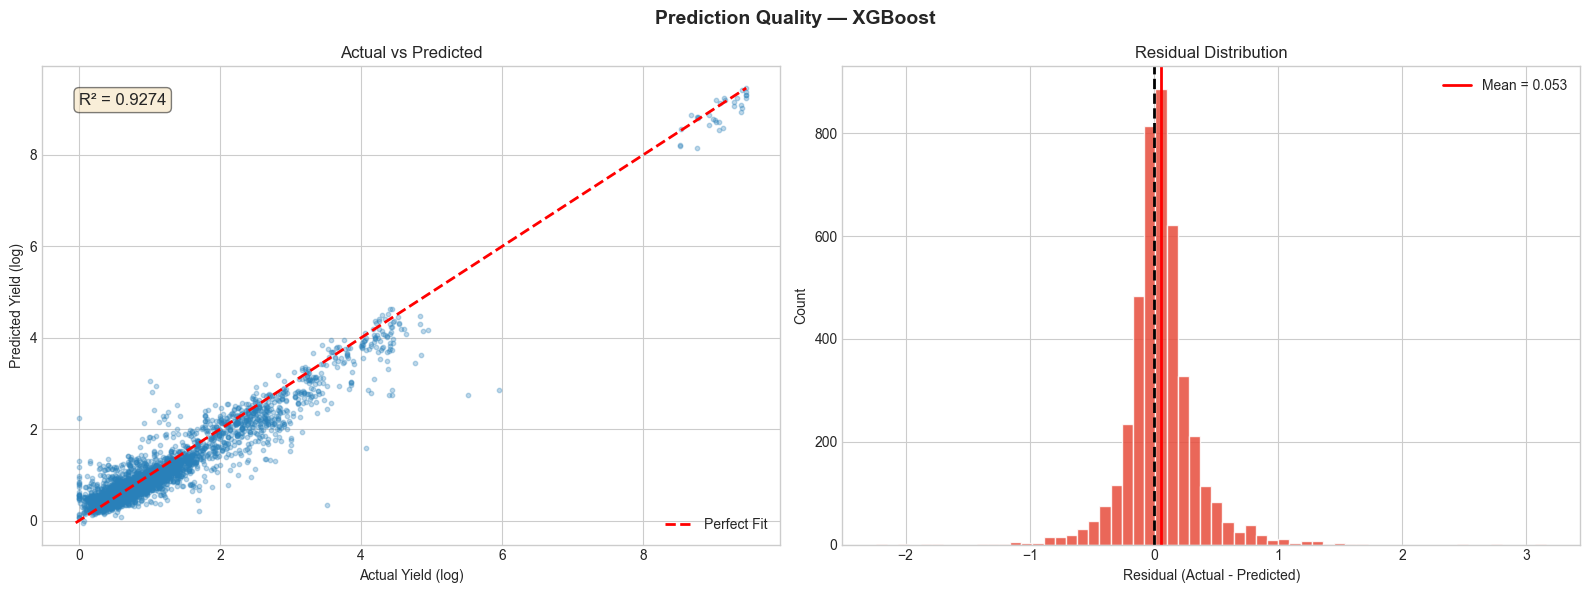

Overall Test Set Metrics:
  R² Score   : 0.9274
  RMSE (log) : 0.2989
  MAE  (log) : 0.1918
  RMSE (real): 172.43 tonnes/ha
  MAE  (real): 13.59 tonnes/ha


In [29]:
best_pred = best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'Prediction Quality — {best_name}',
             fontsize=14, fontweight='bold')

axes[0].scatter(y_test, best_pred, alpha=0.3, s=10, color='#2980B9')
lo = min(y_test.min(), best_pred.min())
hi = max(y_test.max(), best_pred.max())
axes[0].plot([lo,hi],[lo,hi],'r--',lw=2,label='Perfect Fit')
axes[0].set(xlabel='Actual Yield (log)', ylabel='Predicted Yield (log)',
            title='Actual vs Predicted')
axes[0].legend()
axes[0].text(0.05, 0.92,
             f'R² = {r2_score(y_test, best_pred):.4f}',
             transform=axes[0].transAxes, fontsize=12,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

residuals = y_test - best_pred
axes[1].hist(residuals, bins=60, color='#E74C3C',
             edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='black', ls='--', lw=2)
axes[1].axvline(residuals.mean(), color='red', ls='-', lw=2,
                label=f'Mean = {residuals.mean():.3f}')
axes[1].set(xlabel='Residual (Actual - Predicted)',
            ylabel='Count', title='Residual Distribution')
axes[1].legend()

plt.tight_layout()
plt.savefig('outputs/plots/eval_01_predictions.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

print('Overall Test Set Metrics:')
print(f'  R² Score   : {r2_score(y_test, best_pred):.4f}')
print(f'  RMSE (log) : {np.sqrt(mean_squared_error(y_test, best_pred)):.4f}')
print(f'  MAE  (log) : {mean_absolute_error(y_test, best_pred):.4f}')
print(f'  RMSE (real): {np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(best_pred))):.2f} tonnes/ha')
print(f'  MAE  (real): {mean_absolute_error(np.expm1(y_test), np.expm1(best_pred)):.2f} tonnes/ha')

Performance per Climate Cluster:
             Cluster     R2   RMSE    N
     Cluster 0: Arid 0.9102 0.3683 1042
Cluster 1: Semi-Arid 0.9163 0.2908 2450
 Cluster 2: Moderate 0.9718 0.2187  658
    Cluster 3: Humid 0.9429 0.1468  135


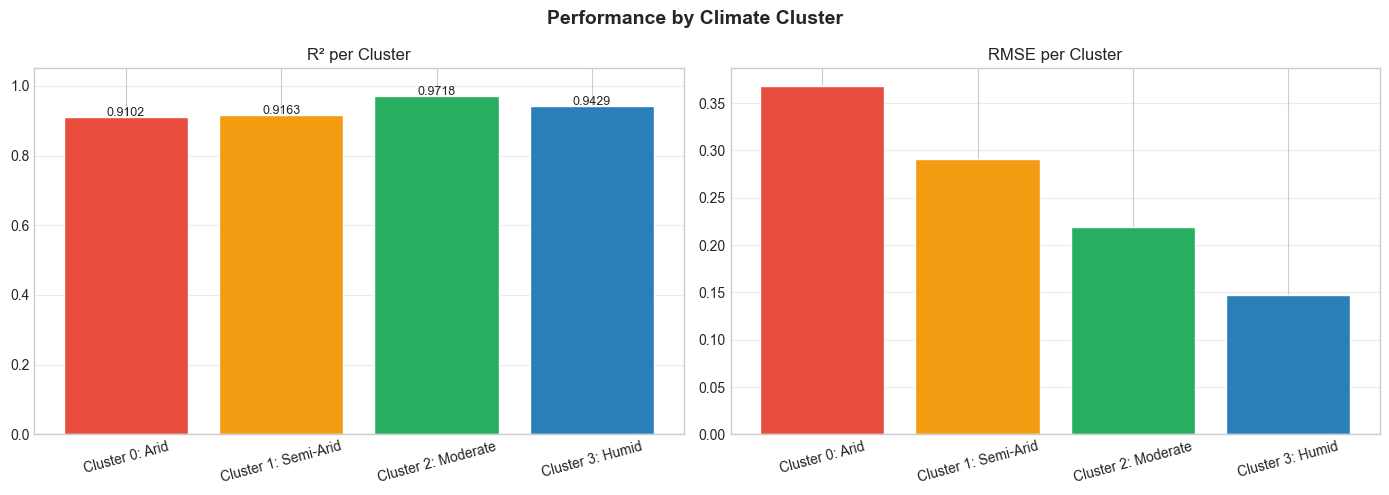

In [30]:
eval_df = test_df.copy()
eval_df['y_pred']  = best_pred
eval_df['abs_err'] = np.abs(eval_df[TARGET_COL] - eval_df['y_pred'])

cluster_perf = []
for c in sorted(eval_df[CLUSTER_COL].dropna().unique()):
    sub  = eval_df[eval_df[CLUSTER_COL] == c]
    ss   = np.sum((sub[TARGET_COL] - sub[TARGET_COL].mean())**2)
    sr   = np.sum((sub[TARGET_COL] - sub['y_pred'])**2)
    r2   = 1 - sr/ss if ss > 0 else 0
    rmse = np.sqrt(np.mean((sub[TARGET_COL] - sub['y_pred'])**2))
    cluster_perf.append({
        'Cluster': f'Cluster {int(c)}: {CLUSTER_LABELS.get(int(c),"")}',
        'R2':   round(r2,   4),
        'RMSE': round(rmse, 4),
        'N':    len(sub)
    })

cp_df = pd.DataFrame(cluster_perf)
print('Performance per Climate Cluster:')
print(cp_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Performance by Climate Cluster', fontsize=14, fontweight='bold')
clrs = list(CLUSTER_COLOR_MAP.values())[:len(cp_df)]
bars = axes[0].bar(cp_df['Cluster'], cp_df['R2'], color=clrs, edgecolor='white')
for bar, val in zip(bars, cp_df['R2']):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
                 f'{val:.4f}', ha='center', fontsize=9)
axes[0].set(title='R² per Cluster', ylim=(0, 1.05))
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', alpha=0.4)
axes[1].bar(cp_df['Cluster'], cp_df['RMSE'], color=clrs, edgecolor='white')
axes[1].set(title='RMSE per Cluster')
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/plots/eval_02_cluster_performance.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

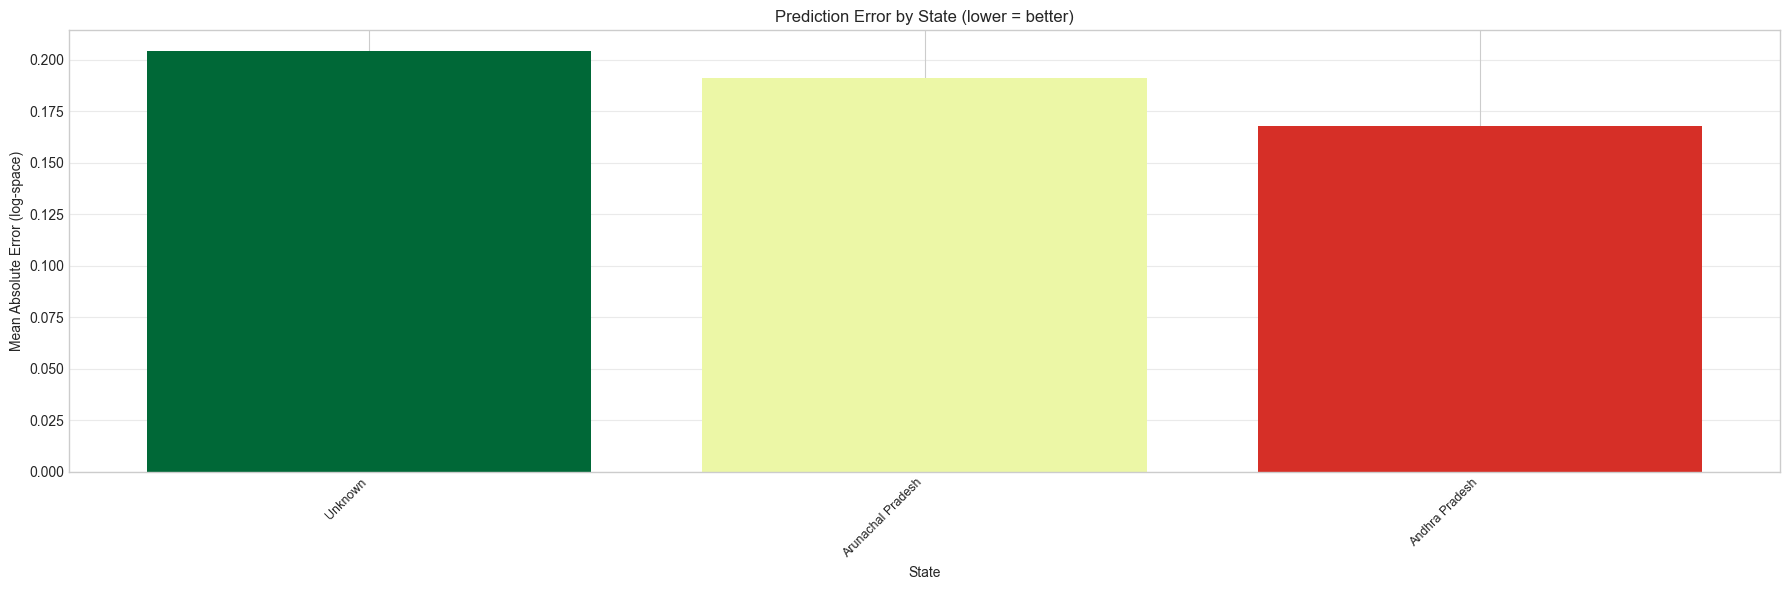

Top 5 easiest states to predict:
State_Name
Unknown              0.203943
Arunachal Pradesh    0.190864
Andhra Pradesh       0.167575

Top 5 hardest states to predict:
State_Name
Unknown              0.203943
Arunachal Pradesh    0.190864
Andhra Pradesh       0.167575


In [31]:
le_state = encoders[STATE_COL]
valid = eval_df[STATE_COL].between(0, len(le_state.classes_)-1)
eval_df['State_Name'] = 'Unknown'
eval_df.loc[valid, 'State_Name'] = le_state.inverse_transform(
    eval_df.loc[valid, STATE_COL].astype(int))

state_err = (eval_df.groupby('State_Name')['abs_err']
             .mean()
             .sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(18, 6))
ax.bar(state_err.index, state_err.values,
       color=plt.cm.RdYlGn_r(np.linspace(0, 0.9, len(state_err))))
ax.set(xlabel='State', ylabel='Mean Absolute Error (log-space)',
       title='Prediction Error by State (lower = better)')
plt.xticks(rotation=45, ha='right', fontsize=9)
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/plots/eval_03_error_by_state.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

print('Top 5 easiest states to predict:')
print(state_err.tail(5).to_string())
print('\nTop 5 hardest states to predict:')
print(state_err.head(5).to_string())

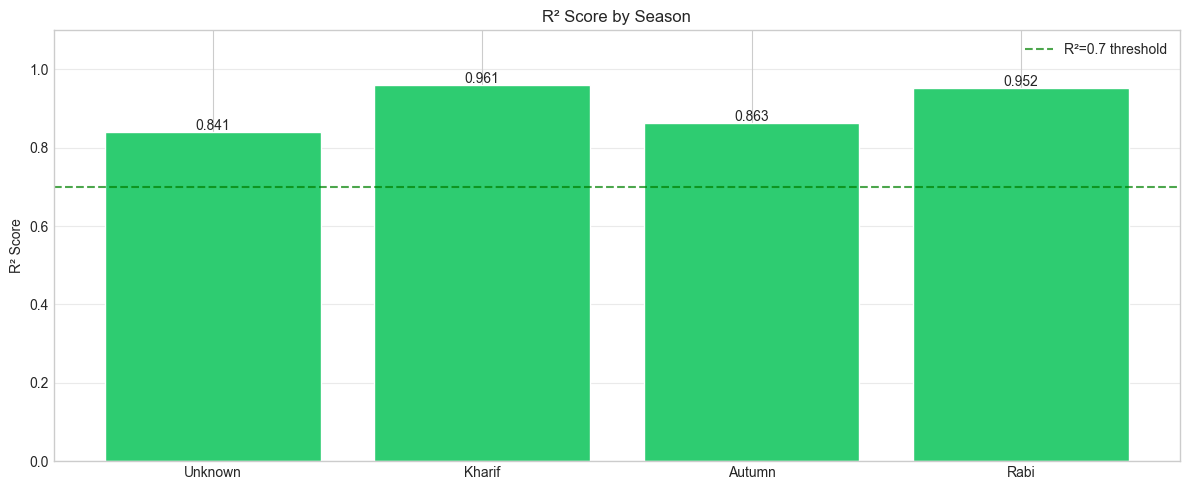

In [32]:
le_season = encoders[SEASON_COL]
valid_s = eval_df[SEASON_COL].between(0, len(le_season.classes_)-1)
eval_df['Season_Name'] = 'Unknown'
eval_df.loc[valid_s, 'Season_Name'] = le_season.inverse_transform(
    eval_df.loc[valid_s, SEASON_COL].astype(int))

season_r2 = {}
for s in eval_df['Season_Name'].unique():
    sub = eval_df[eval_df['Season_Name'] == s]
    if len(sub) < 5:
        continue
    ss = np.sum((sub[TARGET_COL] - sub[TARGET_COL].mean())**2)
    sr = np.sum((sub[TARGET_COL] - sub['y_pred'])**2)
    season_r2[s] = round(1 - sr/ss, 4) if ss > 0 else 0

fig, ax = plt.subplots(figsize=(12, 5))
seasons = list(season_r2.keys())
scores  = list(season_r2.values())
c_map   = ['#2ECC71' if s>=0.7 else '#E67E22' if s>=0.5 else '#E74C3C'
           for s in scores]
bars = ax.bar(seasons, scores, color=c_map, edgecolor='white')
for bar, val in zip(bars, scores):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f'{val:.3f}', ha='center', fontsize=10)
ax.axhline(0.7, color='green', ls='--', alpha=0.7, label='R²=0.7 threshold')
ax.set(title='R² Score by Season', ylabel='R² Score', ylim=(0, 1.1))
ax.legend()
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/plots/eval_04_r2_by_season.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

Computing learning curve ...
   10% of train → Train R²=0.9996  Test R²=0.7197
   22% of train → Train R²=0.9986  Test R²=0.7939
   35% of train → Train R²=0.9973  Test R²=0.8448
   48% of train → Train R²=0.9953  Test R²=0.8558
   61% of train → Train R²=0.9937  Test R²=0.8775
   74% of train → Train R²=0.9915  Test R²=0.8962
   87% of train → Train R²=0.9899  Test R²=0.9208
  100% of train → Train R²=0.9881  Test R²=0.9274


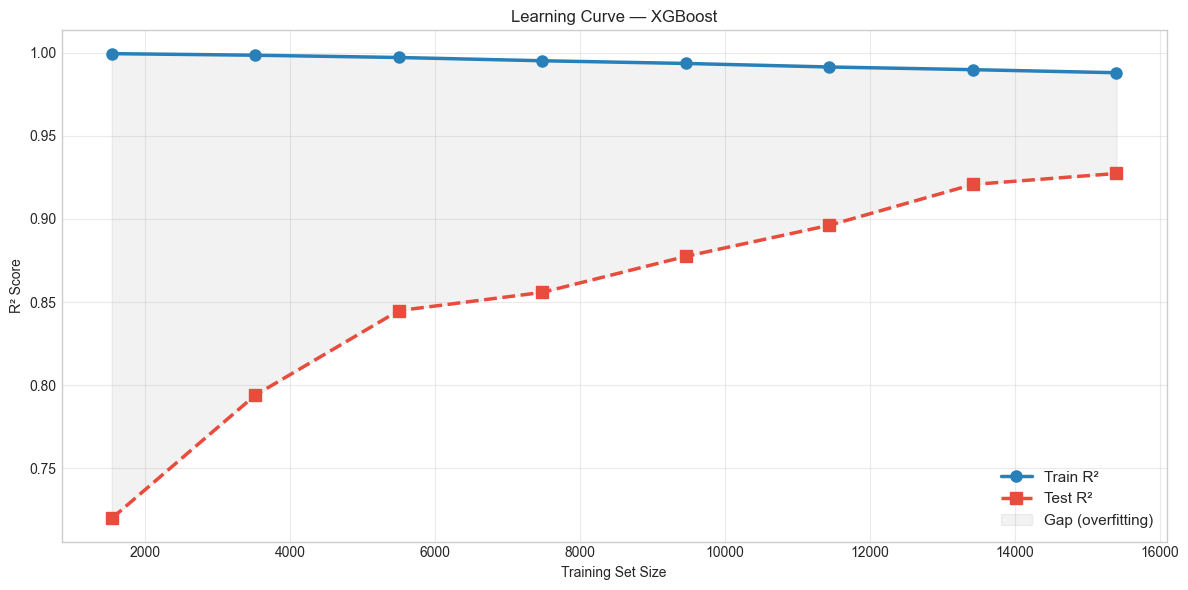

In [33]:
sizes  = np.linspace(0.1, 1.0, 8)
tr_r2s = []
te_r2s = []

print('Computing learning curve ...')
for frac in sizes:
    n   = int(len(X_train) * frac)
    m_c = type(best_model)(**best_model.get_params())
    m_c.fit(X_train[:n], y_train[:n])
    tr_r2s.append(r2_score(y_train[:n], m_c.predict(X_train[:n])))
    te_r2s.append(r2_score(y_test,      m_c.predict(X_test)))
    print(f'  {int(frac*100):3d}% of train → Train R²={tr_r2s[-1]:.4f}  Test R²={te_r2s[-1]:.4f}')

ns = (sizes * len(X_train)).astype(int)
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(ns, tr_r2s, 'o-', color='#2980B9', lw=2.5, ms=8, label='Train R²')
ax.plot(ns, te_r2s, 's--', color='#E74C3C', lw=2.5, ms=8, label='Test R²')
ax.fill_between(ns, tr_r2s, te_r2s, alpha=0.1, color='gray',
                label='Gap (overfitting)')
ax.set(xlabel='Training Set Size', ylabel='R² Score',
       title=f'Learning Curve — {best_name}')
ax.legend(fontsize=11)
ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/plots/eval_05_learning_curve.png',
            dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

In [34]:
r2     = r2_score(y_test, best_pred)
rmse   = np.sqrt(mean_squared_error(y_test, best_pred))
mae    = mean_absolute_error(y_test, best_pred)
rmse_r = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(best_pred)))
mae_r  = mean_absolute_error(np.expm1(y_test), np.expm1(best_pred))

report = f"""
{'='*55}
  CROP YIELD PREDICTION — FINAL EVALUATION REPORT
{'='*55}
  Best Model       : {best_name}
  Train years      : 1997 – {TRAIN_CUTOFF_YEAR}
  Test years       : {TRAIN_CUTOFF_YEAR+1} – 2020
  Train samples    : {len(X_train):,}
  Test samples     : {len(X_test):,}
  Features used    : {len(FEATURE_COLS)}
{'─'*55}
  R² Score         : {r2:.4f}
  RMSE (log-space) : {rmse:.4f}
  MAE  (log-space) : {mae:.4f}
  RMSE (real)      : {rmse_r:.2f} tonnes/ha
  MAE  (real)      : {mae_r:.2f} tonnes/ha
{'='*55}
"""
print(report)

os.makedirs('outputs', exist_ok=True)
with open('outputs/evaluation_report.txt', 'w', encoding='utf-8') as f:  # ✅ only change
    f.write(report)
print('✅ Report saved → outputs/evaluation_report.txt')

results_df.to_csv('outputs/model_results.csv')
print('✅ All model results → outputs/model_results.csv')


  CROP YIELD PREDICTION — FINAL EVALUATION REPORT
  Best Model       : XGBoost
  Train years      : 1997 – 2015
  Test years       : 2016 – 2020
  Train samples    : 15,404
  Test samples     : 4,285
  Features used    : 13
───────────────────────────────────────────────────────
  R² Score         : 0.9274
  RMSE (log-space) : 0.2989
  MAE  (log-space) : 0.1918
  RMSE (real)      : 172.43 tonnes/ha
  MAE  (real)      : 13.59 tonnes/ha

✅ Report saved → outputs/evaluation_report.txt
✅ All model results → outputs/model_results.csv


 SECTION 10 — Predict New Crop Yields

In [35]:
def predict_yield(crop, year, season, state, area,
                  rainfall, fertilizer, pesticide):
    eps = 1e-6
    row = {}
    row[CROP_COL]       = crop.strip()
    row[YEAR_COL]       = year
    row[SEASON_COL]     = season.strip()
    row[STATE_COL]      = state.strip()
    row[AREA_COL]       = np.log1p(area)
    row[PRODUCTION_COL] = np.log1p(area)
    row[RAINFALL_COL]   = rainfall
    row[FERTILIZER_COL] = np.log1p(fertilizer)
    row[PESTICIDE_COL]  = np.log1p(pesticide)
    row[TARGET_COL]     = 0

    # Climate cluster
    cid = state_cluster_map.get(state.strip(), 1)
    row[CLUSTER_COL] = cid

    # Engineered features
    row['Fertilizer_per_Area']        = row[FERTILIZER_COL] / (row[AREA_COL] + eps)
    row['Pesticide_per_Area']         = row[PESTICIDE_COL]  / (row[AREA_COL] + eps)
    row['Fertilizer_Pesticide_Ratio'] = row[FERTILIZER_COL] / (row[PESTICIDE_COL] + eps)
    row['Production_per_Area']        = row[PRODUCTION_COL] / (row[AREA_COL] + eps)
    row['Year_Trend']                 = year - df_raw[YEAR_COL].min()

    # Encode categoricals
    for col in CATEGORICAL_COLS:
        le  = encoders[col]
        val = str(row[col])
        if val not in le.classes_:
            print(f'  ⚠️  Unknown {col}: "{val}" — using closest match')
            val = le.classes_[0]
        row[col] = le.transform([val])[0]

    # Build feature vector
    X = np.array([[row.get(c, 0) for c in FEATURE_COLS]])

    # Scale
    for i, col in enumerate(FEATURE_COLS):
        if col in scale_cols:
            idx    = scale_cols.index(col)
            X[0,i] = (X[0,i] - scaler.mean_[idx]) / (scaler.scale_[idx] + eps)

    y_log  = best_model.predict(X)[0]
    y_real = float(np.expm1(y_log))

    return {
        'Crop'                        : crop,
        'State'                       : state,
        'Season'                      : season,
        'Year'                        : year,
        'Climate Zone'                : f'Cluster {cid}: {CLUSTER_LABELS.get(cid,"")}',
        'Predicted Yield (tonnes/ha)' : round(y_real, 4),
        'Predicted Yield (log-space)' : round(float(y_log), 4),
    }

print('✅ predict_yield() function ready!')

✅ predict_yield() function ready!


In [36]:
test_cases = [
    dict(crop='Rice',      year=2022, season='Kharif',
         state='Assam',       area=60000,  rainfall=2100,
         fertilizer=5500000,  pesticide=18000),
    dict(crop='Wheat',     year=2022, season='Rabi',
         state='Punjab',      area=35000,  rainfall=510,
         fertilizer=3200000,  pesticide=8800),
    dict(crop='Maize',     year=2021, season='Kharif',
         state='Karnataka',   area=45000,  rainfall=1200,
         fertilizer=4200000,  pesticide=14000),
    dict(crop='Cotton',    year=2021, season='Kharif',
         state='Maharashtra', area=40000,  rainfall=900,
         fertilizer=3800000,  pesticide=22000),
    dict(crop='Sugarcane', year=2023, season='Whole Year',
         state='Uttar Pradesh', area=22000, rainfall=850,
         fertilizer=2800000,  pesticide=9500),
]

print('='*60)
print('  CROP YIELD PREDICTIONS')
print('='*60)
all_results = []
for tc in test_cases:
    r = predict_yield(**tc)
    all_results.append(r)
    print(f"\n  🌾 {r['Crop']:12s} | {r['State']:17s} | {r['Season']:12s} | {r['Year']}")
    print(f"     Climate Zone : {r['Climate Zone']}")
    print(f"     ➤ Predicted  : {r['Predicted Yield (tonnes/ha)']} tonnes/ha")

print('\n' + '='*60)
pd.DataFrame(all_results)

  CROP YIELD PREDICTIONS

  🌾 Rice         | Assam             | Kharif       | 2022
     Climate Zone : Cluster 2: Moderate
     ➤ Predicted  : 1.0043 tonnes/ha

  🌾 Wheat        | Punjab            | Rabi         | 2022
     Climate Zone : Cluster 0: Arid
     ➤ Predicted  : 1.3253 tonnes/ha

  🌾 Maize        | Karnataka         | Kharif       | 2021
     Climate Zone : Cluster 1: Semi-Arid
     ➤ Predicted  : 1.9528 tonnes/ha
  ⚠️  Unknown Crop: "Cotton" — using closest match

  🌾 Cotton       | Maharashtra       | Kharif       | 2021
     Climate Zone : Cluster 1: Semi-Arid
     ➤ Predicted  : 1.0275 tonnes/ha

  🌾 Sugarcane    | Uttar Pradesh     | Whole Year   | 2023
     Climate Zone : Cluster 0: Arid
     ➤ Predicted  : 56.1888 tonnes/ha



,Crop,State,Season,Year,Climate Zone,Predicted Yield (tonnes/ha),Predicted Yield (log-space)
0,Rice,Assam,Kharif,2022,Cluster 2: Moderate,1.0043,0.6953
1,Wheat,Punjab,Rabi,2022,Cluster 0: Arid,1.3253,0.8438
2,Maize,Karnataka,Kharif,2021,Cluster 1: Semi-Arid,1.9528,1.0828
3,Cotton,Maharashtra,Kharif,2021,Cluster 1: Semi-Arid,1.0275,0.7068
4,Sugarcane,Uttar Pradesh,Whole Year,2023,Cluster 0: Arid,56.1888,4.0464


In [37]:
# ── ✏️  CHANGE THESE VALUES ─────────────────────────────────────
MY_CROP       = 'Rice'          # Crop name
MY_YEAR       = 2024            # Year
MY_SEASON     = 'Kharif'       # Kharif / Rabi / Whole Year / etc.
MY_STATE      = 'Assam'        # Indian state
MY_AREA       = 50000          # Cultivated area in hectares
MY_RAINFALL   = 1800           # Annual rainfall in mm
MY_FERTILIZER = 4000000        # Fertilizer in kg
MY_PESTICIDE  = 12000          # Pesticide in kg
# ─────────────────────────────────────────────────────────────────

result = predict_yield(
    crop=MY_CROP, year=MY_YEAR, season=MY_SEASON,
    state=MY_STATE, area=MY_AREA, rainfall=MY_RAINFALL,
    fertilizer=MY_FERTILIZER, pesticide=MY_PESTICIDE
)

print('='*50)
print('  YOUR CROP YIELD PREDICTION')
print('='*50)
for k, v in result.items():
    print(f'  {k:35s}: {v}')
print('='*50)

# Visual gauge
y_val = result['Predicted Yield (tonnes/ha)']
fig = go.Figure(go.Indicator(
    mode='gauge+number+delta',
    value=min(y_val, 100),
    title={'text': f"{MY_CROP} — {MY_STATE} ({MY_SEASON} {MY_YEAR})",
           'font': {'size': 16}},
    gauge={
        'axis': {'range': [0, 100]},
        'bar':  {'color': '#2ECC71'},
        'steps': [
            {'range': [0,   20],  'color': '#FADBD8'},
            {'range': [20,  50],  'color': '#FDEBD0'},
            {'range': [50,  100], 'color': '#D5F5E3'},
        ],
        'threshold': {'line': {'color': 'red', 'width': 4},
                      'thickness': 0.75, 'value': y_val}
    }
))
fig.update_layout(height=400)
fig.show()

  YOUR CROP YIELD PREDICTION
  Crop                               : Rice
  State                              : Assam
  Season                             : Kharif
  Year                               : 2024
  Climate Zone                       : Cluster 2: Moderate
  Predicted Yield (tonnes/ha)        : 1.0196
  Predicted Yield (log-space)        : 0.7029


SECTION 11 — Summary

In [38]:
print('='*60)
print('  PROJECT COMPLETE — SUMMARY')
print('='*60)
print(f'\n  Best Model   : {best_name}')
print(f'  R² Score     : {r2_score(y_test, best_model.predict(X_test)):.4f}')
print(f'  RMSE (real)  : {np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(best_model.predict(X_test)))):.2f} tonnes/ha')
print()

print('  Saved Models (models/):')
for f in sorted(os.listdir('models')):
    size = os.path.getsize(f'models/{f}') / 1024
    print(f'    {f:35s} {size:6.1f} KB')

print()
print('  Saved Plots (outputs/plots/):')
for f in sorted(os.listdir('outputs/plots')):
    print(f'    {f}')

print()
print('  Saved Reports (outputs/):')
for f in sorted(os.listdir('outputs')):
    if os.path.isfile(f'outputs/{f}'):
        print(f'    {f}')

print()
print('='*60)
print('  To predict a new crop:')
print('  Go back to Cell 10.3, change the values, re-run!')
print('='*60)

  PROJECT COMPLETE — SUMMARY

  Best Model   : XGBoost
  R² Score     : 0.9274
  RMSE (real)  : 172.43 tonnes/ha

  Saved Models (models/):
    best_model.pkl                      3533.6 KB
    cluster_scaler.pkl                     0.7 KB
    encoders.pkl                           2.0 KB
    feature_cols.pkl                       0.2 KB
    gradient_boosting.pkl                915.0 KB
    kmeans_cluster.pkl                     1.0 KB
    lightgbm.pkl                        2445.2 KB
    random_forest.pkl                   78844.5 KB
    ridge_regression.pkl                   0.6 KB
    scale_cols.pkl                         0.1 KB
    scaler.pkl                             1.1 KB
    state_cluster_map.pkl                  0.4 KB
    xgboost.pkl                         3533.6 KB

  Saved Plots (outputs/plots/):
    cluster_01_elbow.png
    cluster_02_zones.png
    eda_01_yield_distribution.png
    eda_02_top_crops.png
    eda_03_season_analysis.png
    eda_04_yearly_trend.png
    eda_

In [39]:
import os
path = '../models'
print("Files found:", os.listdir(path))

Files found: ['best_model.pkl', 'cluster_scaler.pkl', 'encoders.pkl', 'feature_cols.pkl', 'gradient_boosting.pkl', 'kmeans_cluster.pkl', 'lightgbm.pkl', 'random_forest.pkl', 'ridge_regression.pkl', 'scaler.pkl', 'scale_cols.pkl', 'state_cluster_map.pkl', 'xgboost.pkl']
